# Tune: Scalable Hyperparameter Tuning
## Getting Started & Key Concepts
[link1](https://docs.ray.io/en/latest/tune/getting-started.html#tune-tutorial), 
[link2](https://docs.ray.io/en/latest/tune/key-concepts.html)


Prove per integrare un tool di AutoML(HPO) per la Demo. La scelta corrente è Tune.

Idea: Joint HPO & Train parametri rete in modo incrementale (proseguimento dell'idea di Bilge, applicato on the edge e per time series)


In [ ]:
!pip install ray torch torchvision

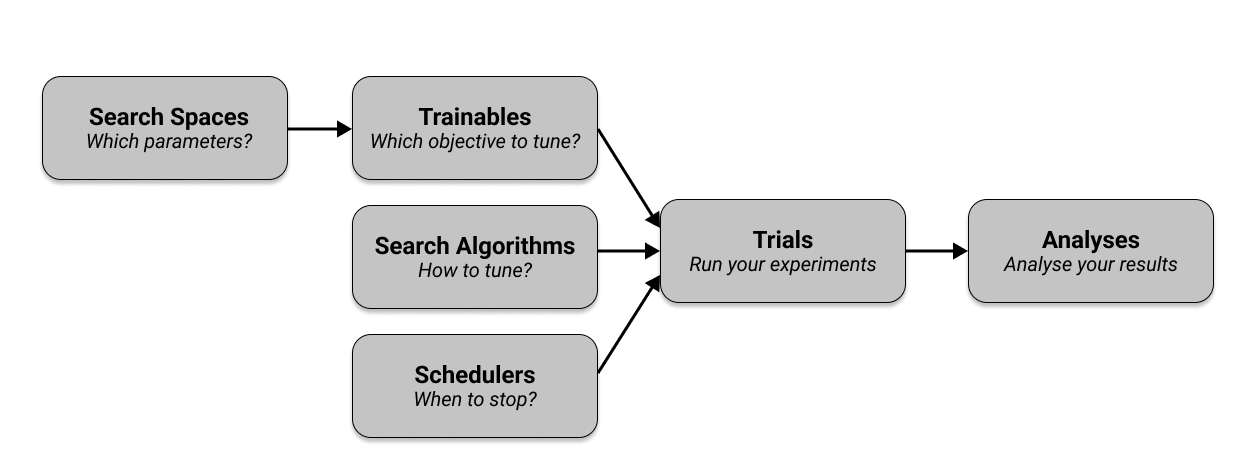

## Setting Up a Pytorch Model to Tune

In [2]:
import numpy as np
import torch
import torch.optim as optim
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch.nn.functional as F

from ray import air, tune
from ray.tune.schedulers import ASHAScheduler

In [3]:
class ConvNet(nn.Module):
    def __init__(self):
        super(ConvNet, self).__init__()
        # In this example, we don't change the model architecture
        # due to simplicity.
        self.conv1 = nn.Conv2d(1, 3, kernel_size=3)
        self.fc = nn.Linear(192, 10)

    def forward(self, x):
        x = F.relu(F.max_pool2d(self.conv1(x), 3))
        x = x.view(-1, 192)
        x = self.fc(x)
        return F.log_softmax(x, dim=1)

In [4]:
# Change these values if you want the training to run quicker or slower
EPOCH_SIZE = 512
TEST_SIZE = 256

def train(model, optimizer, train_loader):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        # We set this just for the example to run quickly.
        if batch_idx * len(data) > EPOCH_SIZE:
            return
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = F.nll_loss(output, target)
        loss.backward()
        optimizer.step()


def test(model, data_loader):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_idx, (data, target) in enumerate(data_loader):
            # We set this just for the example to run quickly.
            if batch_idx * len(data) > TEST_SIZE:
                break
            data, target = data.to(device), target.to(device)
            outputs = model(data)
            _, predicted = torch.max(outputs.data, 1)
            total += target.size(0)
            correct += (predicted == target).sum().item()

    return correct / total

## Setting up Tune

In [5]:
def train_mnist(config):
    # Data Setup
    mnist_transforms = transforms.Compose(
        [transforms.ToTensor(),
         transforms.Normalize((0.1307, ), (0.3081, ))])

    train_loader = DataLoader(
        datasets.MNIST("~/data", train=True, download=True, transform=mnist_transforms),
        batch_size=64,
        shuffle=True)
    test_loader = DataLoader(
        datasets.MNIST("~/data", train=False, transform=mnist_transforms),
        batch_size=64,
        shuffle=True)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # model setup
    model = ConvNet()
    model.to(device)

    #
    optimizer = optim.SGD(
        model.parameters(), lr=config["lr"], momentum=config["momentum"])
    #
    for i in range(10): # multiple run
        train(model, optimizer, train_loader)
        acc = test(model, test_loader)

        # Send the current training result back to Tune
        tune.report(mean_accuracy=acc)

        if i % 5 == 0:
            # This saves the model to the trial directory
            torch.save(model.state_dict(), "./model.pth")

In [ ]:
search_space = {
    "lr": tune.sample_from(lambda spec: 10 ** (-10 * np.random.rand())),
    "momentum": tune.uniform(0.1, 0.9),
}

# Uncomment this to enable distributed execution
# `ray.init(address="auto")`

# Download the dataset first
datasets.MNIST("~/data", train=True, download=True)

tuner = tune.Tuner(
    train_mnist,
    param_space=search_space,
)
results = tuner.fit() #only one trial=tr&eval only 1 configuration!

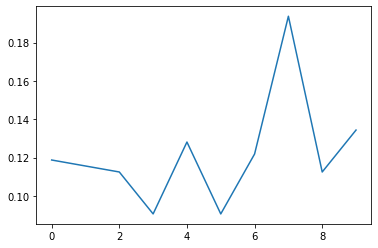

In [7]:
dfs = {result.log_dir: result.metrics_dataframe for result in results}
[d.mean_accuracy.plot() for d in dfs.values()]

## Early Stopping with ASHA
NOTE

In [8]:
tuner = tune.Tuner(
    train_mnist,
    tune_config=tune.TuneConfig(
        num_samples=20,
        scheduler=ASHAScheduler(metric="mean_accuracy", mode="max"),
    ),
    param_space=search_space,
)
results = tuner.fit()

# Obtain a trial dataframe from all run trials of this `tune.run` call.
dfs = {result.log_dir: result.metrics_dataframe for result in results}

2023-01-18 10:24:32,535	WARNING callback.py:108 -- The TensorboardX logger cannot be instantiated because either TensorboardX or one of it's dependencies is not installed. Please make sure you have the latest version of TensorboardX installed: `pip install -U tensorboardx`


Trial name,date,done,episodes_total,experiment_id,hostname,iterations_since_restore,mean_accuracy,node_ip,pid,time_since_restore,time_this_iter_s,time_total_s,timestamp,timesteps_since_restore,timesteps_total,training_iteration,trial_id,warmup_time
train_mnist_4c6a7_00000,2023-01-18_10-24-47,True,,ecb3da9a898c400a92a2dc9f1546d963,f38c1ad2a230,10,0.125,172.28.0.12,5579,8.18431,0.405856,8.18431,1674037487,0,,10,4c6a7_00000,0.0050211
train_mnist_4c6a7_00001,2023-01-18_10-24-44,True,,a81e3d4f7f0c4923b8fcbca7647828b8,f38c1ad2a230,1,0.059375,172.28.0.12,5642,0.722757,0.722757,0.722757,1674037484,0,,1,4c6a7_00001,0.00548959
train_mnist_4c6a7_00002,2023-01-18_10-24-44,True,,a81e3d4f7f0c4923b8fcbca7647828b8,f38c1ad2a230,1,0.084375,172.28.0.12,5642,0.567857,0.567857,0.567857,1674037484,0,,1,4c6a7_00002,0.00548959
train_mnist_4c6a7_00003,2023-01-18_10-24-49,True,,a81e3d4f7f0c4923b8fcbca7647828b8,f38c1ad2a230,10,0.621875,172.28.0.12,5642,4.2975,0.45164,4.2975,1674037489,0,,10,4c6a7_00003,0.00548959
train_mnist_4c6a7_00004,2023-01-18_10-24-51,True,,ecb3da9a898c400a92a2dc9f1546d963,f38c1ad2a230,10,0.9,172.28.0.12,5579,4.37301,0.42243,4.37301,1674037491,0,,10,4c6a7_00004,0.0050211
train_mnist_4c6a7_00005,2023-01-18_10-24-50,True,,a81e3d4f7f0c4923b8fcbca7647828b8,f38c1ad2a230,4,0.178125,172.28.0.12,5642,1.74874,0.432864,1.74874,1674037490,0,,4,4c6a7_00005,0.00548959
train_mnist_4c6a7_00006,2023-01-18_10-24-51,True,,a81e3d4f7f0c4923b8fcbca7647828b8,f38c1ad2a230,1,0.13125,172.28.0.12,5642,0.456502,0.456502,0.456502,1674037491,0,,1,4c6a7_00006,0.00548959
train_mnist_4c6a7_00007,2023-01-18_10-24-55,True,,a81e3d4f7f0c4923b8fcbca7647828b8,f38c1ad2a230,10,0.81875,172.28.0.12,5642,4.41147,0.434087,4.41147,1674037495,0,,10,4c6a7_00007,0.00548959
train_mnist_4c6a7_00008,2023-01-18_10-24-56,True,,ecb3da9a898c400a92a2dc9f1546d963,f38c1ad2a230,10,0.928125,172.28.0.12,5579,4.39397,0.436412,4.39397,1674037496,0,,10,4c6a7_00008,0.0050211
train_mnist_4c6a7_00009,2023-01-18_10-24-56,True,,a81e3d4f7f0c4923b8fcbca7647828b8,f38c1ad2a230,1,0.103125,172.28.0.12,5642,0.498163,0.498163,0.498163,1674037496,0,,1,4c6a7_00009,0.00548959


2023-01-18 10:25:03,355	INFO tune.py:762 -- Total run time: 30.85 seconds (30.54 seconds for the tuning loop).


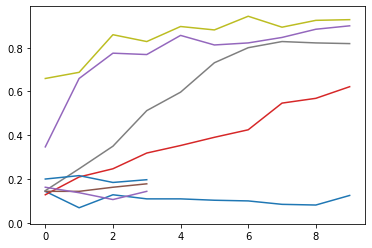

In [9]:
# Plot by epoch
ax = None  # This plots everything on the same plot
for d in dfs.values():
    ax = d.mean_accuracy.plot(ax=ax, legend=False)

In [12]:
!tensorboard --logdir {logdir}

2023-01-18 10:25:23.295575: E tensorflow/stream_executor/cuda/cuda_driver.cc:271] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected

NOTE: Using experimental fast data loading logic. To disable, pass
    "--load_fast=false" and report issues on GitHub. More details:
    https://github.com/tensorflow/tensorboard/issues/4784

Serving TensorBoard on localhost; to expose to the network, use a proxy or pass --bind_all
TensorBoard 2.9.1 at http://localhost:6006/ (Press CTRL+C to quit)
^C


## Search Algorithms in Tune

In [13]:
from hyperopt import hp # wrappa libreria open-source esterna (HPO)
from ray.tune.search.hyperopt import HyperOptSearch # per usare "esterni" search algoritms

space = { # NOTA: space configuration secondo la libreria "nativa"
    "lr": hp.loguniform("lr", -10, -1),
    "momentum": hp.uniform("momentum", 0.1, 0.9),
}

hyperopt_search = HyperOptSearch(space, metric="mean_accuracy", mode="max") # wrappando usi stessa "procedura"

tuner = tune.Tuner(
    train_mnist,
    tune_config=tune.TuneConfig(
        num_samples=10,
        search_alg=hyperopt_search,
    ),
)
results = tuner.fit()

# To enable GPUs, use this instead:
# analysis = tune.run(
#     train_mnist, config=search_space, resources_per_trial={'gpu': 1})


2023-01-18 10:32:37,162	WARNING callback.py:108 -- The TensorboardX logger cannot be instantiated because either TensorboardX or one of it's dependencies is not installed. Please make sure you have the latest version of TensorboardX installed: `pip install -U tensorboardx`


Trial name,date,done,episodes_total,experiment_id,experiment_tag,hostname,iterations_since_restore,mean_accuracy,node_ip,pid,time_since_restore,time_this_iter_s,time_total_s,timestamp,timesteps_since_restore,timesteps_total,training_iteration,trial_id,warmup_time
train_mnist_045470c3,2023-01-18_10-33-02,True,,684c36f1849a465289285d2a94a12362,"7_lr=0.0411,momentum=0.8390",f38c1ad2a230,10,0.86875,172.28.0.12,7878,4.27749,0.394377,4.27749,1674037982,0,,10,045470c3,0.00457311
train_mnist_0a045eb1,2023-01-18_10-33-04,True,,1f8e1d91dc16406aaf1f49e47b325a02,"8_lr=0.1435,momentum=0.4646",f38c1ad2a230,10,0.9125,172.28.0.12,7931,4.12214,0.42363,4.12214,1674037984,0,,10,0a045eb1,0.00506473
train_mnist_2ef3e229,2023-01-18_10-32-58,True,,684c36f1849a465289285d2a94a12362,"5_lr=0.0061,momentum=0.5739",f38c1ad2a230,10,0.71875,172.28.0.12,7878,4.24,0.429577,4.24,1674037978,0,,10,2ef3e229,0.00457311
train_mnist_432c0758,2023-01-18_10-33-07,True,,1f8e1d91dc16406aaf1f49e47b325a02,"10_lr=0.0016,momentum=0.3784",f38c1ad2a230,10,0.4125,172.28.0.12,7931,3.52451,0.236453,3.52451,1674037987,0,,10,432c0758,0.00506473
train_mnist_4371d6a4,2023-01-18_10-33-06,True,,684c36f1849a465289285d2a94a12362,"9_lr=0.0020,momentum=0.4041",f38c1ad2a230,10,0.49375,172.28.0.12,7878,4.13139,0.382676,4.13139,1674037986,0,,10,4371d6a4,0.00457311
train_mnist_716541ba,2023-01-18_10-32-54,True,,684c36f1849a465289285d2a94a12362,"3_lr=0.1063,momentum=0.4848",f38c1ad2a230,10,0.915625,172.28.0.12,7878,4.35399,0.426139,4.35399,1674037974,0,,10,716541ba,0.00457311
train_mnist_7f77fcda,2023-01-18_10-32-49,True,,684c36f1849a465289285d2a94a12362,"1_lr=0.2326,momentum=0.4707",f38c1ad2a230,10,0.88125,172.28.0.12,7878,7.53562,0.426065,7.53562,1674037969,0,,10,7f77fcda,0.00457311
train_mnist_b46549a0,2023-01-18_10-33-00,True,,1f8e1d91dc16406aaf1f49e47b325a02,"6_lr=0.0148,momentum=0.8417",f38c1ad2a230,10,0.875,172.28.0.12,7931,4.39527,0.414625,4.39527,1674037980,0,,10,b46549a0,0.00506473
train_mnist_c6bfaac5,2023-01-18_10-32-55,True,,1f8e1d91dc16406aaf1f49e47b325a02,"4_lr=0.0001,momentum=0.2006",f38c1ad2a230,10,0.1,172.28.0.12,7931,4.35486,0.397749,4.35486,1674037975,0,,10,c6bfaac5,0.00506473
train_mnist_f8695655,2023-01-18_10-32-51,True,,1f8e1d91dc16406aaf1f49e47b325a02,"2_lr=0.0194,momentum=0.7714",f38c1ad2a230,10,0.9,172.28.0.12,7931,4.58687,0.429217,4.58687,1674037971,0,,10,f8695655,0.00506473


2023-01-18 10:33:07,915	INFO tune.py:762 -- Total run time: 30.78 seconds (30.60 seconds for the tuning loop).


## Evaluate your model


In [15]:
import os

# prendi il the best
logdir = results.get_best_result("mean_accuracy", mode="max").log_dir
state_dict = torch.load(os.path.join(logdir, "model.pth"))

# load best model
model = ConvNet()
model.load_state_dict(state_dict)

<All keys matched successfully>

## Final Remarks